<a href="https://colab.research.google.com/github/Wizako-01/AI-Assisted-Liver-Tumour-Segmentation-and-Ablation-Planning/blob/main/lits_interventional_oncology_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CT liver tumour segmentation and simulated ablation-margin analysis

**Complete Google Colab research prototype.** Dataset: [LiTS PNG on Kaggle](https://www.kaggle.com/datasets/andrewmvd/lits-png). Run cells from top to bottom with a GPU runtime.

**Important scientific boundary:** These are resized 2D PNG slices without calibrated pixel spacing, vascular annotations, needle tracks, treatment records, or ablation outcomes. This notebook reports *pixel-space geometric coverage under synthetic margin scenarios*, **not** physical millimetre margins, safety, actual treatment planning, clinical efficacy, or treatment response. There is no patient-level intervention ground truth. Use only for retrospective computational research.

The experiment uses **study-level separation** to avoid training/testing leakage. We sample a manageable number of slices from each partition for a Colab T4. Increasing sample caps and epochs improves coverage at higher computation cost. Set a random seed for reproducibility.

In [9]:
!pip -q install kagglehub pandas pillow scipy scikit-learn matplotlib tqdm
import os, random, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('/content/lits_ablation_results'); OUT.mkdir(exist_ok=True, parents=True)
print('Device:', DEVICE)
print('Output:', OUT)

Device: cuda
Output: /content/lits_ablation_results


In [10]:
import kagglehub
ROOT = Path(kagglehub.dataset_download('andrewmvd/lits-png'))
csv_candidates = sorted(ROOT.rglob('lits_df.csv'))
assert csv_candidates, f'Cannot locate lits_df.csv under {ROOT}'
CSV = csv_candidates[0]
df = pd.read_csv(CSV)
print('Data root:', ROOT)
print('CSV:', CSV)
print('Rows:', len(df))
print('Columns:', df.columns.tolist())
display(df.head(3))

Data root: /root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6
CSV: /root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/lits_df.csv
Rows: 58638
Columns: ['filepath', 'liver_maskpath', 'tumor_maskpath', 'study_number', 'instance_number', 'liver_mask_empty', 'tumor_mask_empty']


,filepath,liver_maskpath,tumor_maskpath,study_number,instance_number,liver_mask_empty,tumor_mask_empty
0,../input/lits-png/dataset_6/volume-0_0.png,../input/lits-png/dataset_6/segmentation-0_liv...,../input/lits-png/dataset_6/segmentation-0_les...,0,0,False,False
1,../input/lits-png/dataset_6/volume-0_1.png,../input/lits-png/dataset_6/segmentation-0_liv...,../input/lits-png/dataset_6/segmentation-0_les...,0,1,False,False
2,../input/lits-png/dataset_6/volume-0_2.png,../input/lits-png/dataset_6/segmentation-0_liv...,../input/lits-png/dataset_6/segmentation-0_les...,0,2,False,False


In [11]:
# The metadata paths may contain Kaggle's /input/lits-png prefix.
# Resolve against this dataset root rather than trusting stale absolute paths.
REQUIRED = ['filepath','liver_maskpath','tumor_maskpath','study_number']
missing = set(REQUIRED).difference(df.columns)
assert not missing, f'Missing columns: {missing}'

def resolve_asset(value):
    raw = str(value).replace('\\', '/')
    p = Path(raw)
    if p.is_file(): return p
    marker = '/lits-png/'
    relative = raw.split(marker,1)[1] if marker in raw else raw.lstrip('./')
    candidates = [ROOT / relative, ROOT / Path(relative).name,
                  CSV.parent / relative, CSV.parent / Path(relative).name]
    for candidate in candidates:
        if candidate.is_file(): return candidate
    return None

for field, dest in [('filepath','image_path'),('liver_maskpath','liver_path'),
                    ('tumor_maskpath','tumor_path')]:
    df[dest] = [str(x) if x is not None else '' for x in tqdm(
        (resolve_asset(v) for v in df[field]), total=len(df), desc=dest)]
valid = df[['image_path','liver_path','tumor_path']].ne('').all(axis=1)
print('Valid rows:', valid.sum(), '/', len(df))
assert valid.sum() > 1000, 'Too many missing images: inspect actual Kaggle folder layout.'
df = df.loc[valid].reset_index(drop=True)
df['study_number'] = df['study_number'].astype(str)
df['positive'] = ~df['tumor_mask_empty'].astype(str).str.lower().eq('true') if 'tumor_mask_empty' in df else True
print('Studies:', df.study_number.nunique(), 'Positive slices:', int(df.positive.sum()))

image_path:   0%|          | 0/58638 [00:00<?, ?it/s]

liver_path:   0%|          | 0/58638 [00:00<?, ?it/s]

tumor_path:   0%|          | 0/58638 [00:00<?, ?it/s]

Valid rows: 0 / 58638


AssertionError: Too many missing images: inspect actual Kaggle folder layout.

In [12]:
from pathlib import Path

print("ROOT:", ROOT)

print("\nTop-level files and folders:")
for p in list(ROOT.iterdir())[:20]:
    print(p.name, "Folder" if p.is_dir() else "File")

print("\nChecking PNG files:")
png_files = list(ROOT.rglob("*.png"))

print("PNG files found:", len(png_files))

if png_files:
    print("\nFirst 5 PNG files:")
    for p in png_files[:5]:
        print(p)
else:
    print("WARNING: No PNG files were found!")

ROOT: /root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6

Top-level files and folders:
lits_df.csv File
lits_train.csv File
lits_test.csv File
dataset_6 Folder
lits_probe.csv File

Checking PNG files:
PNG files found: 175914

First 5 PNG files:
/root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6/volume-119_48.png
/root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6/segmentation-96_livermask_267.png
/root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6/volume-30_180.png
/root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6/volume-130_423.png
/root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6/volume-7_386.png


In [13]:
from pathlib import Path

# Actual location of the image files
IMAGE_ROOT = ROOT / "dataset_6" / "dataset_6"

print("Image directory:", IMAGE_ROOT)
print("Directory exists:", IMAGE_ROOT.exists())

def resolve_asset(old_path):
    filename = Path(str(old_path).replace("\\", "/")).name
    return str(IMAGE_ROOT / filename)

df["image_path"] = df["filepath"].apply(resolve_asset)
df["liver_path"] = df["liver_maskpath"].apply(resolve_asset)
df["tumor_path"] = df["tumor_maskpath"].apply(resolve_asset)

# Verify that the images exist
valid = (
    df["image_path"].apply(lambda p: Path(p).is_file()) &
    df["liver_path"].apply(lambda p: Path(p).is_file()) &
    df["tumor_path"].apply(lambda p: Path(p).is_file())
)

print("Valid rows:", valid.sum(), "/", len(df))

assert valid.sum() > 1000, "Image paths could not be resolved."

df = df.loc[valid].reset_index(drop=True)

df["study_number"] = df["study_number"].astype(str)

df["positive"] = ~(
    df["tumor_mask_empty"]
    .astype(str)
    .str.lower()
    .eq("true")
)

print("Studies:", df["study_number"].nunique())
print("Tumour-positive slices:", df["positive"].sum())

print("\nDATASET READY!")

Image directory: /root/.cache/kagglehub/datasets/andrewmvd/lits-png/versions/6/dataset_6/dataset_6
Directory exists: True
Valid rows: 58638 / 58638
Studies: 131
Tumour-positive slices: 51524

DATASET READY!


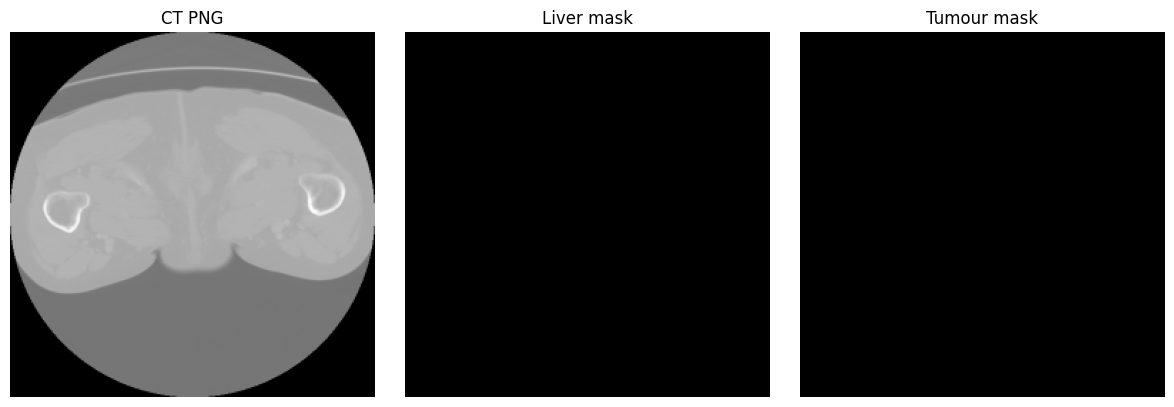

Image dimensions: (256, 256) tumour positive pixels: 0


In [14]:
# Preview an actual slice plus both ground-truth masks.
sample = df[df.positive].iloc[0]
def read_gray(path):
    return np.asarray(Image.open(path).convert('L'), dtype=np.uint8)
im, liver, tumor = [read_gray(sample[c]) for c in ['image_path','liver_path','tumor_path']]
fig, ax = plt.subplots(1,3,figsize=(12,4))
for a,arr,title in zip(ax,[im,liver,tumor],['CT PNG','Liver mask','Tumour mask']):
    a.imshow(arr,cmap='gray'); a.set_title(title); a.axis('off')
plt.tight_layout(); plt.savefig(OUT/'dataset_preview.png',dpi=180); plt.show()
print('Image dimensions:', im.shape, 'tumour positive pixels:', (tumor>0).sum())

In [15]:
# Split by study, BEFORE selecting slices; never randomly split individual slices.
studies = np.array(sorted(df.study_number.unique()))
train_studies, temp_studies = train_test_split(studies, test_size=0.30, random_state=SEED)
val_studies, test_studies = train_test_split(temp_studies, test_size=0.50, random_state=SEED)

def sample_rows(ids, cap):
    part = df[df.study_number.isin(ids)].copy()
    pos = part[part.positive]; neg = part[~part.positive]
    # Mix lesion-positive and lesion-negative images; no oversampling of one patient's slices.
    npos = min(len(pos), round(cap*0.7))
    nneg = min(len(neg), cap-npos)
    keep = pd.concat([pos.sample(n=npos,random_state=SEED) if npos else pos.iloc[:0],
                      neg.sample(n=nneg,random_state=SEED) if nneg else neg.iloc[:0]])
    return keep.sample(frac=1,random_state=SEED).reset_index(drop=True)

# Increase caps after a successful first run, if memory/time permits.
train_df = sample_rows(train_studies, 4800)
val_df = sample_rows(val_studies, 800)
test_df = sample_rows(test_studies, 800)
assert set(train_df.study_number).isdisjoint(val_df.study_number)
assert set(train_df.study_number).isdisjoint(test_df.study_number)
assert set(val_df.study_number).isdisjoint(test_df.study_number)
for name, part in [('train',train_df),('val',val_df),('test',test_df)]:
    print(name, 'slices:',len(part),'studies:',part.study_number.nunique(),'lesion-positive:',int(part.positive.sum()))
    part[['study_number','filepath','tumor_maskpath']].to_csv(OUT/f'{name}_manifest.csv',index=False)

train slices: 4800 studies: 91 lesion-positive: 3360
val slices: 800 studies: 20 lesion-positive: 560
test slices: 800 studies: 20 lesion-positive: 560


In [16]:
class LiTSSlices(Dataset):
    def __init__(self, frame, augment=False):
        self.rows = frame.reset_index(drop=True)
        self.augment = augment
    def __len__(self): return len(self.rows)
    def __getitem__(self, idx):
        r = self.rows.iloc[idx]
        x = read_gray(r.image_path).astype(np.float32)/255.0
        y = (read_gray(r.tumor_path)>0).astype(np.float32)
        # Match dataset's expected 256 x 256 shape without applying interpolation to masks.
        if x.shape != (256,256):
            x = np.asarray(Image.fromarray((x*255).astype(np.uint8)).resize((256,256),Image.Resampling.BILINEAR),dtype=np.float32)/255
            y = np.asarray(Image.fromarray(y.astype(np.uint8)).resize((256,256),Image.Resampling.NEAREST),dtype=np.float32)
        if self.augment:
            if random.random()<0.5: x=np.fliplr(x); y=np.fliplr(y)
            if random.random()<0.5: x=np.flipud(x); y=np.flipud(y)
            k=random.randint(0,3); x=np.rot90(x,k); y=np.rot90(y,k)
        return torch.from_numpy(x.copy()[None]), torch.from_numpy(y.copy()[None])

BATCH = 16
train_loader = DataLoader(LiTSSlices(train_df,True),batch_size=BATCH,shuffle=True,num_workers=2,pin_memory=(DEVICE.type=='cuda'))
val_loader = DataLoader(LiTSSlices(val_df),batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=(DEVICE.type=='cuda'))
test_loader = DataLoader(LiTSSlices(test_df),batch_size=BATCH,shuffle=False,num_workers=2,pin_memory=(DEVICE.type=='cuda'))
print('Batches:',len(train_loader),len(val_loader),len(test_loader))

Batches: 300 50 50


Epoch 1/5:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 1: train=0.6086, val=0.5270


Epoch 2/5:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 2: train=0.5161, val=0.5072


Epoch 3/5:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 3: train=0.5045, val=0.5027


Epoch 4/5:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 4: train=0.4981, val=0.4971


Epoch 5/5:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 5: train=0.4918, val=0.4850


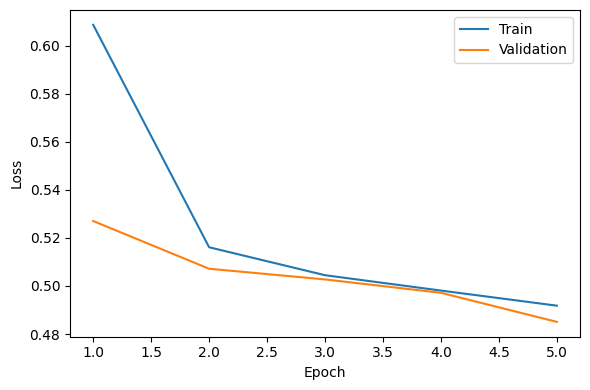

<All keys matched successfully>

In [17]:
# Compact 2D U-Net, feasible on a Colab T4.
class Block(nn.Module):
    def __init__(self, inp, out):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(inp,out,3,padding=1),nn.BatchNorm2d(out),nn.ReLU(True),
                               nn.Conv2d(out,out,3,padding=1),nn.BatchNorm2d(out),nn.ReLU(True))
    def forward(self,x): return self.net(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.a=Block(1,16); self.b=Block(16,32); self.c=Block(32,64); self.mid=Block(64,128)
        self.u3=Block(128+64,64); self.u2=Block(64+32,32); self.u1=Block(32+16,16)
        self.out=nn.Conv2d(16,1,1); self.pool=nn.MaxPool2d(2)
    def forward(self,x):
        a=self.a(x); b=self.b(self.pool(a)); c=self.c(self.pool(b)); m=self.mid(self.pool(c))
        x=self.u3(torch.cat([nn.functional.interpolate(m,size=c.shape[-2:],mode='bilinear',align_corners=False),c],1))
        x=self.u2(torch.cat([nn.functional.interpolate(x,size=b.shape[-2:],mode='bilinear',align_corners=False),b],1))
        x=self.u1(torch.cat([nn.functional.interpolate(x,size=a.shape[-2:],mode='bilinear',align_corners=False),a],1))
        return self.out(x)

model = UNet().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
bce = nn.BCEWithLogitsLoss()
def loss_fn(logits,y):
    prob = torch.sigmoid(logits)
    overlap=(prob*y).sum((1,2,3)); total=prob.sum((1,2,3))+y.sum((1,2,3))
    dice_loss = 1-(2*overlap+1)/(total+1)
    return .5*bce(logits,y)+.5*dice_loss.mean()

@torch.no_grad()
def evaluate_loss(loader):
    model.eval(); loss_total=0; n=0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        loss_total+=loss_fn(model(x),y).item()*len(x); n+=len(x)
    return loss_total/max(n,1)

EPOCHS=5
best=float('inf'); history=[]
for epoch in range(1,EPOCHS+1):
    model.train(); running=0; count=0
    for x,y in tqdm(train_loader,desc=f'Epoch {epoch}/{EPOCHS}',leave=False):
        x,y=x.to(DEVICE),y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss=loss_fn(model(x),y)
        loss.backward(); optimizer.step()
        running+=loss.item()*len(x); count+=len(x)
    train_loss=running/max(count,1); val_loss=evaluate_loss(val_loader)
    history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss})
    print(f'Epoch {epoch}: train={train_loss:.4f}, val={val_loss:.4f}')
    if val_loss<best:
        best=val_loss
        torch.save({'state_dict':model.state_dict(),'seed':SEED,'epoch':epoch},OUT/'best_unet.pt')

pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
plt.figure(figsize=(6,4))
plt.plot([h['epoch'] for h in history],[h['train_loss'] for h in history],label='Train')
plt.plot([h['epoch'] for h in history],[h['val_loss'] for h in history],label='Validation')
plt.legend();plt.xlabel('Epoch');plt.ylabel('Loss');plt.tight_layout()
plt.savefig(OUT/'loss_curve.png',dpi=180);plt.show()
model.load_state_dict(torch.load(OUT/'best_unet.pt',map_location=DEVICE,weights_only=True)['state_dict'])

In [18]:
# Threshold selection on validation data ONLY; reserve the test set for final scoring.
@torch.no_grad()
def predict_probabilities(loader):
    model.eval(); probs=[]; truths=[]
    for x,y in tqdm(loader,desc='Inference'):
        p=torch.sigmoid(model(x.to(DEVICE))).cpu().numpy()[:,0]
        probs.extend(p); truths.extend(y.numpy()[:,0])
    return np.asarray(probs,dtype=np.float32),np.asarray(truths,dtype=np.uint8)

def slice_dice(pred, gt):
    s=pred.sum()+gt.sum()
    return float((2*np.logical_and(pred,gt).sum())/s) if s else 1.0

vp,vy=predict_probabilities(val_loader)
thresholds=np.arange(.2,.81,.1)
val_scores=[np.mean([slice_dice(p>=t,y>0) for p,y in zip(vp,vy)]) for t in thresholds]
THRESHOLD=float(thresholds[int(np.argmax(val_scores))])
print('Selected validation threshold:',THRESHOLD)
print('Validation Dice across thresholds:',dict(zip(np.round(thresholds,2),np.round(val_scores,3))))
del vp,vy

Inference:   0%|          | 0/50 [00:00<?, ?it/s]

Selected validation threshold: 0.8000000000000003
Validation Dice across thresholds: {np.float64(0.2): np.float64(0.333), np.float64(0.3): np.float64(0.351), np.float64(0.4): np.float64(0.359), np.float64(0.5): np.float64(0.371), np.float64(0.6): np.float64(0.388), np.float64(0.7): np.float64(0.412), np.float64(0.8): np.float64(0.447)}


Inference:   0%|          | 0/50 [00:10<?, ?it/s]

Mean slice Dice: 0.4341 Mean study Dice: 0.3833
Mean slice IoU: 0.4135
Positive GT slices only, Dice: 0.1886
Presence confusion matrix (rows true, cols predicted):
[[302 258]
 [ 34 206]]


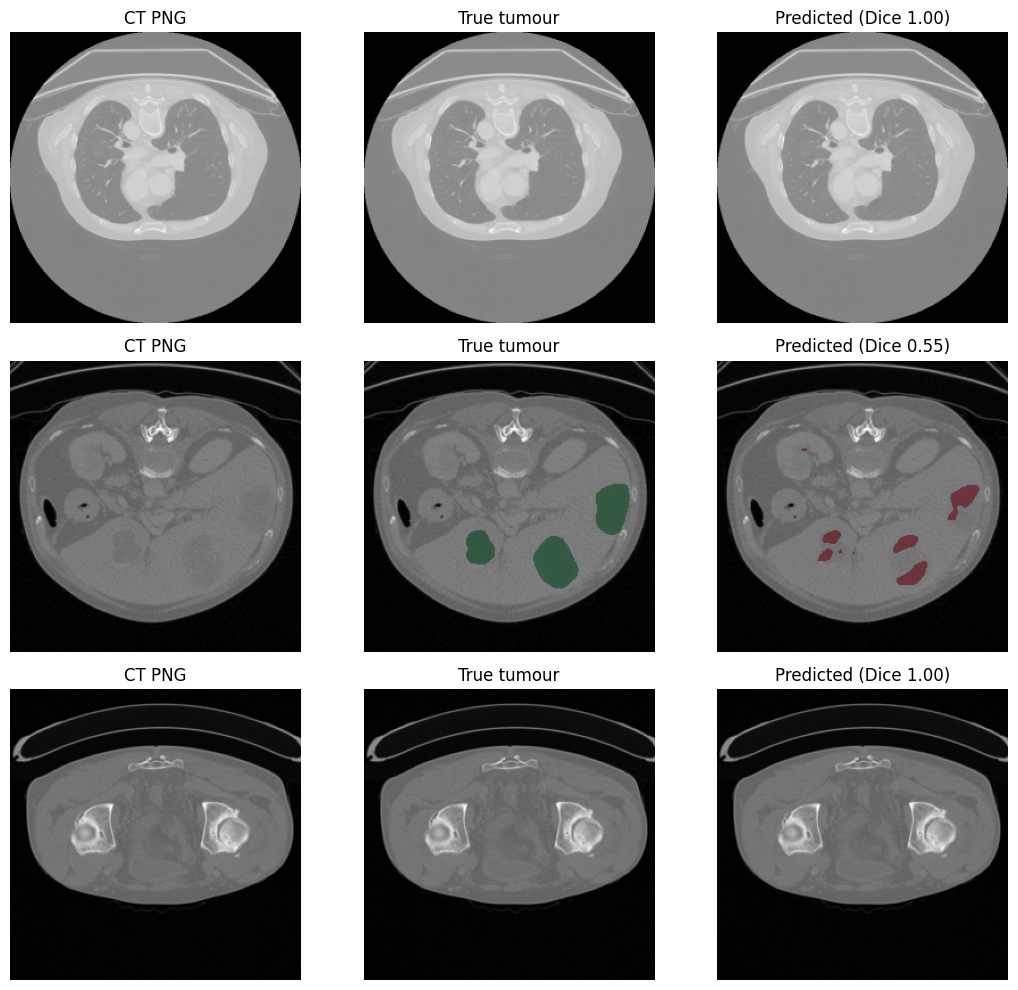

In [19]:
tp,ty=predict_probabilities(test_loader)
pred=tp>=THRESHOLD
gt=ty>0
eps=1e-8
records=[]
for i in range(len(test_df)):
    p=pred[i]; y=gt[i]
    intersection=np.logical_and(p,y).sum(); union=np.logical_or(p,y).sum()
    records.append({'study_number':test_df.iloc[i].study_number,
                    'slice_index':i,'dice':slice_dice(p,y),
                    'iou':float(intersection/union) if union else 1.,
                    'gt_positive':bool(y.any()),'pred_positive':bool(p.any())})
metrics=pd.DataFrame(records)
metrics.to_csv(OUT/'test_slice_metrics.csv',index=False)
per_study=metrics.groupby('study_number').agg(mean_dice=('dice','mean'),mean_iou=('iou','mean'),n_slices=('dice','size'))
per_study.to_csv(OUT/'test_study_metrics.csv')
print('Mean slice Dice:',round(metrics.dice.mean(),4),'Mean study Dice:',round(per_study.mean_dice.mean(),4))
print('Mean slice IoU:',round(metrics.iou.mean(),4))
print('Positive GT slices only, Dice:',round(metrics.loc[metrics.gt_positive,'dice'].mean(),4))
print('Presence confusion matrix (rows true, cols predicted):')
print(confusion_matrix(metrics.gt_positive,metrics.pred_positive,labels=[False,True]))

fig,axs=plt.subplots(3,3,figsize=(11,10))
selected=np.linspace(0,len(test_df)-1,3,dtype=int)
for row,i in enumerate(selected):
    im=read_gray(test_df.iloc[i].image_path)
    axs[row,0].imshow(im,cmap='gray');axs[row,0].set_title('CT PNG')
    axs[row,1].imshow(im,cmap='gray');axs[row,1].imshow(np.ma.masked_where(~gt[i],gt[i]),cmap='Greens',alpha=.55,vmin=0,vmax=1);axs[row,1].set_title('True tumour')
    axs[row,2].imshow(im,cmap='gray');axs[row,2].imshow(np.ma.masked_where(~pred[i],pred[i]),cmap='Reds',alpha=.55,vmin=0,vmax=1);axs[row,2].set_title(f'Predicted (Dice {metrics.iloc[i].dice:.2f})')
for a in axs.flat: a.axis('off')
plt.tight_layout();plt.savefig(OUT/'segmentation_examples.png',dpi=170);plt.show()

## Synthetic ablation-margin sensitivity analysis (pixels only)

For tumour prediction mask **P** and a synthetic, circular structuring element of radius *r pixels*, define an illustrative ablation region **A(r) = dilate(P, r)**. Compare with the separate ground truth mask **G**: **coverage = |G ∩ A(r)| / |G|** and **spill ratio = |A(r) \ G| / |A(r)|**. These are *geometric proxies*, not clinically meaningful injury or treatment predictions. No organ-at-risk, vessel, heat-sink, device physics, or true ablation contour is available. The known ground-truth mask is used **only to evaluate** the synthetic region, not to plan it.

Empty-tumour slices are excluded from this analysis. Overlapping 2D slices are not independent patients.

Synthetic margins:   0%|          | 0/800 [00:00<?, ?it/s]

          tumour_coverage              spill_fraction             
                     mean    std count           mean    std count
radius_px                                                         
0                   0.234  0.273    18          0.597  0.338    18
3                   0.310  0.307    18          0.637  0.328    18
6                   0.356  0.326    18          0.671  0.318    18
10                  0.410  0.342    18          0.701  0.308    18


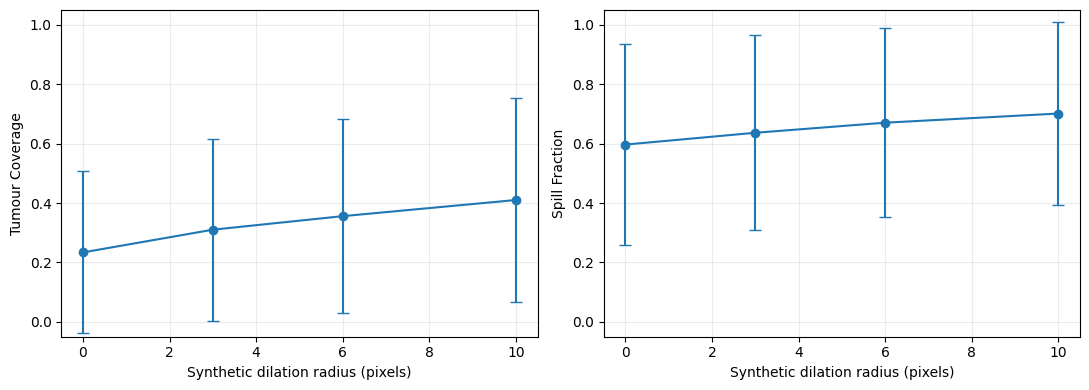

In [20]:
def disk(radius):
    y,x=np.ogrid[-radius:radius+1,-radius:radius+1]
    return x*x+y*y<=radius*radius

RADII=[0,3,6,10] # PIXELS, NOT millimetres
ablation=[]
for i in tqdm(range(len(test_df)),desc='Synthetic margins'):
    if not gt[i].any(): continue
    y=gt[i]; p=pred[i]
    for r in RADII:
        area=ndi.binary_dilation(p,structure=disk(r)) if r else p
        covered=np.logical_and(y,area).sum()/max(1,y.sum())
        spill=np.logical_and(area,~y).sum()/max(1,area.sum())
        ablation.append({'slice_index':i,'study_number':test_df.iloc[i].study_number,
                         'radius_px':r,'tumour_coverage':covered,'spill_fraction':spill,
                         'plan_empty':not p.any()})
ablation=pd.DataFrame(ablation)
ablation.to_csv(OUT/'synthetic_margin_slice_metrics.csv',index=False)
summary=ablation.groupby(['study_number','radius_px'])[['tumour_coverage','spill_fraction']].mean().reset_index()
study_aggregate=summary.groupby('radius_px')[['tumour_coverage','spill_fraction']].agg(['mean','std','count'])
print(study_aggregate.round(3))
study_aggregate.to_csv(OUT/'synthetic_margin_study_summary.csv')

fig,ax=plt.subplots(1,2,figsize=(11,4))
for j,col in enumerate(['tumour_coverage','spill_fraction']):
    stats=summary.groupby('radius_px')[col].agg(['mean','std'])
    ax[j].errorbar(stats.index,stats['mean'],yerr=stats['std'],marker='o',capsize=4)
    ax[j].set(xlabel='Synthetic dilation radius (pixels)',ylabel=col.replace('_',' ').title(),ylim=(-.05,1.05))
    ax[j].grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT/'synthetic_margin_tradeoff.png',dpi=180);plt.show()

In [21]:
# Illustrative segmentation perturbation sensitivity:
# eroding and dilating predicted contours changes the synthetic region.
# This is NOT a calibrated model uncertainty estimate.
SENS_RADIUS=6
sensitivity=[]
for i in tqdm(range(len(test_df)),desc='Perturbation analysis'):
    if not gt[i].any(): continue
    base=pred[i]
    variants={'eroded_2px':ndi.binary_erosion(base,structure=disk(2)),
              'original':base,
              'dilated_2px':ndi.binary_dilation(base,structure=disk(2))}
    for variant,p in variants.items():
        region=ndi.binary_dilation(p,structure=disk(SENS_RADIUS))
        sensitivity.append({'slice_index':i,'study_number':test_df.iloc[i].study_number,
                            'variant':variant,'coverage':np.logical_and(region,gt[i]).sum()/gt[i].sum()})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(OUT/'perturbation_sensitivity.csv',index=False)
print(sensitivity.groupby('variant').coverage.agg(['mean','std','count']).round(3))

with open(OUT/'run_config.json','w') as f:
    json.dump({'dataset':'andrewmvd/lits-png','seed':SEED,'train_studies':list(map(str,train_studies)),
               'val_studies':list(map(str,val_studies)),'test_studies':list(map(str,test_studies)),
               'train_cap':4800,'val_cap':800,'test_cap':800,'epochs':EPOCHS,
               'threshold_from_validation':THRESHOLD,'synthetic_margin_radius_pixels':RADII,
               'not_calibrated_mm':True,'no_clinical_outcomes':True},f,indent=2)
print('Saved all outputs in',OUT)

Perturbation analysis:   0%|          | 0/800 [00:00<?, ?it/s]

              mean    std  count
variant                         
dilated_2px  0.419  0.382    240
eroded_2px   0.318  0.333    240
original     0.388  0.365    240
Saved all outputs in /content/lits_ablation_results


In [22]:
# Download all outputs as one ZIP to preserve results beyond this Colab session.
import shutil
archive=shutil.make_archive('/content/lits_ablation_results','zip',root_dir=OUT)
print('Archive:',archive)
from google.colab import files
files.download(archive)

Archive: /content/lits_ablation_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>